# Junk Food Binary Classification with KNN

This notebook implements a **K-Nearest Neighbors (KNN)** model for binary image classification (`junk-food-ad` vs `non-junk-food-ad`) using the **leakage-aware binary dataset** (`binary-dataset.zip`, folders `ad` / `non_ad` + `groups.csv`) stored in Google Drive.

The train/val/test split is **group-aware**: all frames of the same ad creative or source video stay in the same split, so near-duplicate frames cannot leak from train into validation/test.

## Before you start

Make sure you have access to GPU. In case of any problems, navigate to `Edit` -> `Notebook settings` -> `Hardware accelerator`, set it to `GPU`, click `Save` and try again.

In [1]:
!nvidia-smi

Mon Nov 23 03:24:30 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   38C    P8             13W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [2]:
import os
HOME = os.getcwd()
print("HOME:", HOME)

HOME: /content


In [3]:
!mkdir -p {HOME}/datasets
%cd {HOME}/datasets


/content/datasets


## Install packages using pip

In [4]:
!pip install torch==2.9.0 torchvision==0.24.0 scikit-learn==1.6.1 tqdm==4.67.1 matplotlib seaborn

## Load dataset from Google Drive

Mount your Google Drive and add a Colab secret named `BINARY_DATASET_ZIP_PATH` (Secrets panel - the key icon in the left sidebar) pointing to `binary-dataset.zip` in Drive (absolute, e.g. `/content/drive/MyDrive/datasets/binary-dataset.zip`, or relative to `/content/drive`, e.g. `MyDrive/datasets/binary-dataset.zip`).

The zip (produced by `unhealthy-dataset-generator`) contains `ad/` (junk food ads), `non_ad/` (everything else) and `groups.csv`, which assigns every frame to a **group**: frames of the same ad creative (`ad_XXXX`) or of the same source video (`non_ad_<video>`). `groups.csv` may also list frames that were capped/rebalanced out of the zip; those rows are ignored. The notebook checks that every image has exactly one group and that the CSV label matches its folder.

In [5]:
import os
import shutil
import zipfile
import numpy as np
import pandas as pd
from google.colab import drive, userdata

drive.mount('/content/drive')

# Path to binary-dataset.zip in your Google Drive. Add BINARY_DATASET_ZIP_PATH in Colab's
# "Secrets" panel (key icon in the left sidebar), e.g.
# /content/drive/MyDrive/Colab Notebooks/Tesis/datasets/binary-dataset.zip
_zip_secret = userdata.get('BINARY_DATASET_ZIP_PATH').strip()
DATASET_ZIP_PATH = (_zip_secret if _zip_secret.startswith('/content/')
                    else os.path.join('/content/drive', _zip_secret.lstrip('/')))
if not os.path.isfile(DATASET_ZIP_PATH):
    raise FileNotFoundError(f"Dataset zip not found: {DATASET_ZIP_PATH}")

# Copy the zip to local Colab storage and extract it there (much faster than reading from Drive).
# Always start from a clean folder so a previous/partial extraction can't leave stale files behind.
LOCAL_ZIP_PATH = "/content/binary-dataset.zip"
EXTRACT_ROOT = "/content/binary_dataset"
shutil.copy(DATASET_ZIP_PATH, LOCAL_ZIP_PATH)
if os.path.exists(EXTRACT_ROOT):
    shutil.rmtree(EXTRACT_ROOT)
with zipfile.ZipFile(LOCAL_ZIP_PATH, "r") as zf:
    zf.extractall(EXTRACT_ROOT)

# Locate the folder that contains ad/, non_ad/ and groups.csv
DATASET_ROOT = None
for current_dir, subdirs, file_names in os.walk(EXTRACT_ROOT):
    if "ad" in subdirs and "non_ad" in subdirs and "groups.csv" in file_names:
        DATASET_ROOT = current_dir
        break
if DATASET_ROOT is None:
    raise FileNotFoundError("Could not find 'ad/', 'non_ad/' and 'groups.csv' inside the extracted dataset.")
print("Dataset folder:", DATASET_ROOT)

# Map source folders to binary class names. The positive class maps to index 0.
CLASS_FOLDERS = {
    "ad": "junk-food-ad",          # positive class
    "non_ad": "non-junk-food-ad",  # negative class
}
POSITIVE_CLASS = "junk-food-ad"
NEGATIVE_CLASS = "non-junk-food-ad"
IMG_EXTS = (".jpg", ".jpeg", ".png")

# Images actually present in the zip
disk_rows = []
for folder, class_name in CLASS_FOLDERS.items():
    folder_path = os.path.join(DATASET_ROOT, folder)
    for file_name in sorted(os.listdir(folder_path)):
        if file_name.lower().endswith(IMG_EXTS):
            disk_rows.append({"image_name": file_name, "folder": folder, "class_name": class_name,
                              "path": os.path.join(folder_path, file_name)})
disk_df = pd.DataFrame(disk_rows)
duplicated = disk_df[disk_df["image_name"].duplicated(keep=False)]
if not duplicated.empty:
    raise ValueError(f"Image names repeated across folders: {duplicated['image_name'].unique()[:10].tolist()}")

groups_df = pd.read_csv(os.path.join(DATASET_ROOT, "groups.csv"), dtype=str, encoding="utf-8-sig")
missing_cols = {"image_name", "label", "group"} - set(groups_df.columns)
if missing_cols:
    raise ValueError(f"groups.csv is missing columns: {sorted(missing_cols)}")
groups_df["image_name"] = groups_df["image_name"].str.strip()
groups_df = groups_df[groups_df["image_name"].isin(set(disk_df["image_name"]))]
if groups_df["image_name"].duplicated().any():
    raise ValueError("groups.csv has duplicated rows for images in the zip: "
                     f"{groups_df.loc[groups_df['image_name'].duplicated(), 'image_name'].tolist()[:10]}")

dataset_df = disk_df.merge(groups_df[["image_name", "label", "group"]], on="image_name", how="left")
no_row = dataset_df[dataset_df["group"].isna() | (dataset_df["group"].str.strip() == "")]
if not no_row.empty:
    raise ValueError(f"{len(no_row)} images have no group in groups.csv, e.g. {no_row['image_name'].tolist()[:10]}")
mismatch = dataset_df[dataset_df["label"].str.strip() != dataset_df["folder"]]
if not mismatch.empty:
    raise ValueError(f"{len(mismatch)} images have a groups.csv label different from their folder, "
                     f"e.g. {mismatch[['image_name', 'label', 'folder']].head().to_dict('records')}")
dataset_df["group"] = dataset_df["group"].str.strip()
dataset_df = dataset_df.drop(columns="label")

print(f"Images: {len(dataset_df)} | groups: {dataset_df['group'].nunique()}")
print(dataset_df.groupby("class_name").agg(images=("image_name", "size"), groups=("group", "nunique")).to_string())

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Dataset folder: /content/binary_dataset
Images: 5272 | groups: 112
                  images  groups
class_name                      
junk-food-ad        2636      86
non-junk-food-ad    2636      26


In [6]:
%cd {HOME}

/content


## Dataset split (group-aware, no leakage)

Frames of the same ad creative or the same source video are near-duplicates, so a random per-image split would leak them between train and evaluation. We therefore assign **whole groups** to **train/val/test** (target 70/15/15 of the frames of each class, fixed seed 42): no group appears in more than one split. Shares are approximate because groups have different sizes. The positive class is `junk-food-ad` (from the `ad/` folder) and the negative class is `non-junk-food-ad` (from the `non_ad/` folder).

The KNN code below calls the validation split `valid`.

In [7]:
import numpy as np
import pandas as pd

SEED = 42
SPLIT_FRACTIONS = {"train": 0.70, "val": 0.15, "test": 0.15}
# When a class has fewer groups than splits, its groups go to the splits in this order:
# 1 group -> train; 2 groups -> train + test (so the class is still evaluated); >= 3 -> all splits.
SUPPORT_ORDER = ("train", "test", "val")


def stratified_group_split(frame, label_col, group_col="group", fractions=SPLIT_FRACTIONS,
                           support_order=SUPPORT_ORDER, seed=SEED):
    """Assign whole groups to splits while keeping the per-class frame shares close to `fractions`.

    Groups (same creative / same source video) are atomic, so near-identical frames never
    cross splits. A group may contain frames of several classes; it is described by its
    per-class frame counts. Classes are processed from the one with the fewest groups to
    the one with the most; each carrier group (largest first, seeded order on ties) goes to
    the split with the largest remaining deficit for that class, then for total frames.
    A repair pass then guarantees every class has at least one group in the splits given by
    `support_order` (moving the smallest donor group that its own split can spare).

    Returns a dict group -> split name.
    """
    splits = list(fractions)
    counts = pd.crosstab(frame[group_col], frame[label_col])
    order = counts.index.to_numpy().copy()
    np.random.default_rng(seed).shuffle(order)
    counts = counts.loc[order]
    classes = list(counts.columns)
    sizes = counts.sum(axis=1)

    class_target = {s: counts.sum(axis=0) * f for s, f in fractions.items()}
    frame_target = {s: sizes.sum() * f for s, f in fractions.items()}
    filled = {s: pd.Series(0.0, index=classes) for s in splits}
    assignment = {}

    n_carriers = (counts > 0).sum(axis=0).sort_values(kind="stable")
    for cls in n_carriers.index:
        carriers = [g for g in counts.index if g not in assignment and counts.loc[g, cls] > 0]
        carriers.sort(key=lambda g: -counts.loc[g, cls])
        for g in carriers:
            split = max(splits, key=lambda s: (class_target[s][cls] - filled[s][cls],
                                               frame_target[s] - filled[s].sum()))
            assignment[g] = split
            filled[split] += counts.loc[g]

    def required(cls):
        return [s for s in support_order if s in splits][:min(int(n_carriers[cls]), len(splits))]

    def carriers_in(cls, split):
        return sum(1 for g, s in assignment.items() if s == split and counts.loc[g, cls] > 0)

    def can_leave(g, split):
        return all(carriers_in(c, split) > 1 or split not in required(c)
                   for c in classes if counts.loc[g, c] > 0)

    changed = True
    while changed:
        changed = False
        for cls in n_carriers.index:
            for split in required(cls):
                if carriers_in(cls, split):
                    continue
                donors = [g for g, s in assignment.items()
                          if s != split and counts.loc[g, cls] > 0 and can_leave(g, s)]
                if donors:
                    assignment[min(donors, key=lambda g: sizes[g])] = split
                    changed = True

    for cls in n_carriers.index:
        missing = [s for s in required(cls) if not carriers_in(cls, s)]
        if missing:
            print(f"  NOTE: class {cls!r} has no group in {missing} (its groups cannot be moved)")
        if n_carriers[cls] < len(splits):
            present = [s for s in splits if carriers_in(cls, s)]
            print(f"  NOTE: class {cls!r} has only {int(n_carriers[cls])} group(s); present in {present}")
    return assignment


def assert_no_group_leakage(frame, group_col="group", split_col="split"):
    splits_per_group = frame.groupby(group_col)[split_col].nunique()
    leaked = splits_per_group[splits_per_group > 1]
    assert leaked.empty, f"LEAKAGE: groups in more than one split: {list(leaked.index)}"


def print_split_summary(frame, label_col, group_col="group", split_col="split"):
    split_names = [s for s in SPLIT_FRACTIONS if s in set(frame[split_col])]
    frames = pd.crosstab(frame[label_col], frame[split_col]).reindex(columns=split_names, fill_value=0)
    groups = (frame.groupby([label_col, split_col])[group_col].nunique().unstack(fill_value=0)
              .reindex(index=frames.index, columns=split_names, fill_value=0))
    table = frames.astype(str) + " (" + groups.astype(str) + " gr)"
    total_groups = frame.groupby(label_col)[group_col].nunique().reindex(frames.index)
    table["total"] = frames.sum(axis=1).astype(str) + " (" + total_groups.astype(str) + " gr)"
    print("Frames (groups) per class and split:")
    print(table.to_string())
    totals = frames.sum(axis=0)
    print("\nFrames per split: " + ", ".join(
        f"{s}={int(totals[s])} ({totals[s] / totals.sum():.1%}, "
        f"{frame.loc[frame[split_col] == s, group_col].nunique()} groups)"
        for s in split_names))


group_to_split = stratified_group_split(dataset_df, label_col="class_name")
dataset_df["split"] = dataset_df["group"].map(group_to_split)
assert dataset_df["split"].notna().all()
assert_no_group_leakage(dataset_df)
# Interleave classes inside every split (reproducible)
dataset_df = dataset_df.sample(frac=1.0, random_state=SEED).reset_index(drop=True)
print_split_summary(dataset_df, label_col="class_name")

# KNN code below uses the split names train/valid/test.
SPLIT_RATIOS = {"train": SPLIT_FRACTIONS["train"], "valid": SPLIT_FRACTIONS["val"], "test": SPLIT_FRACTIONS["test"]}
SPLIT_SOURCES = {"train": "train", "valid": "val", "test": "test"}
classes = [POSITIVE_CLASS, NEGATIVE_CLASS]
image_paths_dict, labels_dict, groups_dict = {}, {}, {}
for part, source in SPLIT_SOURCES.items():
    part_df = dataset_df[dataset_df["split"] == source]
    image_paths_dict[part] = part_df["path"].tolist()
    labels_dict[part] = part_df["class_name"].tolist()
    groups_dict[part] = part_df["group"].tolist()

print("\n" + "="*50)
print("DATASET SUMMARY")
print("="*50)
print(f"\nClasses: {classes}")
print(f"\nDataset parts processed:")

for part in image_paths_dict.keys():
    print(f"\n{part.upper()}:")
    print(f"  Total images: {len(image_paths_dict[part])}")
    print(f"  Total groups: {len(set(groups_dict[part]))}")
    print(f"  Label distribution:")
    for cls in classes:
        count = labels_dict[part].count(cls)
        percentage = (count / len(labels_dict[part]) * 100) if labels_dict[part] else 0
        print(f"    - {cls}: {count} ({percentage:.1f}%)")

Frames (groups) per class and split:
split                    train          val         test         total
class_name                                                            
junk-food-ad      1844 (48 gr)  397 (19 gr)  395 (19 gr)  2636 (86 gr)
non-junk-food-ad  1863 (18 gr)   385 (4 gr)   388 (4 gr)  2636 (26 gr)

Frames per split: train=3707 (70.3%, 66 groups), val=782 (14.8%, 23 groups), test=783 (14.9%, 23 groups)

DATASET SUMMARY

Classes: ['junk-food-ad', 'non-junk-food-ad']

Dataset parts processed:

TRAIN:
  Total images: 3707
  Total groups: 66
  Label distribution:
    - junk-food-ad: 1844 (49.7%)
    - non-junk-food-ad: 1863 (50.3%)

VALID:
  Total images: 782
  Total groups: 23
  Label distribution:
    - junk-food-ad: 397 (50.8%)
    - non-junk-food-ad: 385 (49.2%)

TEST:
  Total images: 783
  Total groups: 23
  Label distribution:
    - junk-food-ad: 395 (50.4%)
    - non-junk-food-ad: 388 (49.6%)


## Feature extraction of training set using pretrained models

KNN itself cannot extract visual features, it only compares numeric vectors.  
Therefore, we use **pretrained** models (without their classification heads) to extract image embeddings of train set.

These embeddings (feature vectors) represent each image in a high-dimensional space that captures visual similarity.  
The extracted features are stored as a NumPy matrix and later fed into the KNN classifier.

In [8]:
import torch
import torchvision.models as models
import torchvision.transforms as transforms
from PIL import Image
from tqdm import tqdm
import numpy as np
from time import perf_counter

feature_extraction_seconds = {'train': {}, 'valid': {}, 'test': {}}

def extract_features(image_paths, model, feature_dim, transform, model_name, split_name):
    if device.type == 'cuda':
        torch.cuda.synchronize()
    started = perf_counter()
    features = []
    with torch.inference_mode():
        for path in tqdm(image_paths, desc=f"Extracting features - {model_name}"):
            with Image.open(path) as img:
                tensor = transform(img.convert("RGB")).unsqueeze(0).to(device)
            feat = model(tensor).reshape(-1).cpu().numpy()
            if feat.shape != (feature_dim,) or not np.isfinite(feat).all():
                raise ValueError(f"Invalid features for {model_name}: {path}, shape={feat.shape}")
            features.append(feat)
    if device.type == 'cuda':
        torch.cuda.synchronize()
    feature_extraction_seconds[split_name][model_name] = perf_counter() - started
    return np.stack(features)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

model_configs = [
    {
        'name': 'ResNeXt-101',
        'loader': lambda: models.resnext101_32x8d(weights=models.ResNeXt101_32X8D_Weights.DEFAULT),
        'modifier': lambda m: torch.nn.Sequential(*list(m.children())[:-1]),
        'transform': models.ResNeXt101_32X8D_Weights.DEFAULT.transforms(),
        'feature_dim': 2048
    },
    {
        'name': 'EfficientNet V2-M',
        'loader': lambda: models.efficientnet_v2_m(weights=models.EfficientNet_V2_M_Weights.DEFAULT),
        'modifier': lambda m: torch.nn.Sequential(*list(m.children())[:-1]),
        'transform': models.EfficientNet_V2_M_Weights.DEFAULT.transforms(),
        'feature_dim': 1280
    },
    {
        'name': 'ConvNeXt Base',
        'loader': lambda: models.convnext_base(weights=models.ConvNeXt_Base_Weights.DEFAULT),
        # Keep the pretrained final normalization and flattening; remove only the linear head.
        'modifier': lambda m: (m.classifier.__setitem__(2, torch.nn.Identity()), m)[1],
        'transform': models.ConvNeXt_Base_Weights.DEFAULT.transforms(),
        'feature_dim': 1024
    },
    {
        'name': 'ViT-B/16',
        'loader': lambda: models.vit_b_16(weights=models.ViT_B_16_Weights.DEFAULT),
        'modifier': lambda m: (setattr(m.heads, 'head', torch.nn.Identity()), m)[1],
        'transform': models.ViT_B_16_Weights.DEFAULT.transforms(),
        'feature_dim': 768
    },
    {
        'name': 'Swin V2-B',
        'loader': lambda: models.swin_v2_b(weights=models.Swin_V2_B_Weights.DEFAULT),
        'modifier': lambda m: torch.nn.Sequential(*list(m.children())[:-1]),
        'transform': models.Swin_V2_B_Weights.DEFAULT.transforms(),
        'feature_dim': 1024
    },
    {
        'name': 'DINOv2',
        'loader': lambda: torch.hub.load('facebookresearch/dinov2', 'dinov2_vitb14'),
        'modifier': lambda m: m,  # No modification needed
        'transform': transforms.Compose([
            transforms.Resize(256, interpolation=transforms.InterpolationMode.BICUBIC),
            transforms.CenterCrop(224),
            transforms.ToTensor(),
            transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
        ]),
        'feature_dim': 768
    }
]

loaded_models = []
for config in model_configs:
    model = config['loader']()
    model = config['modifier'](model)
    model = model.to(device)
    model.eval()
    model.requires_grad_(False)
    loaded_models.append({
        'model': model,
        'name': config['name'],
        'transform': config['transform'],
        'feature_dim': config['feature_dim']
    })

# Extract features for all models on train set
all_features = {}
for model_info in loaded_models:
    features = extract_features(
        image_paths_dict['train'],
        model_info['model'],
        model_info['feature_dim'],
        model_info['transform'],
        model_info['name'], 'train'
    )
    all_features[model_info['name']] = features
    print(f"Feature matrix shape - {model_info['name']}: {features.shape}")

Using device: cuda
Downloading: "https://download.pytorch.org/models/resnext101_32x8d-110c445d.pth" to /root/.cache/torch/hub/checkpoints/resnext101_32x8d-110c445d.pth


100%|██████████| 340M/340M [00:03<00:00, 93.4MB/s]


Downloading: "https://download.pytorch.org/models/efficientnet_v2_m-dc08266a.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_v2_m-dc08266a.pth


100%|██████████| 208M/208M [00:01<00:00, 164MB/s]


Downloading: "https://download.pytorch.org/models/convnext_base-6075fbad.pth" to /root/.cache/torch/hub/checkpoints/convnext_base-6075fbad.pth


100%|██████████| 338M/338M [00:02<00:00, 133MB/s]


... (15 outputs left out)

Extracting features - Swin V2-B: 100%|██████████| 3707/3707 [03:14<00:00, 19.09it/s]


Feature matrix shape - Swin V2-B: (3707, 1024)


Extracting features - DINOv2: 100%|██████████| 3707/3707 [02:01<00:00, 30.63it/s]

Feature matrix shape - DINOv2: (3707, 768)


## "Training" the KNN Classifiers

KNN is "trained" (fitted actually) using a simple distance-based rule:
- Each image is classified based on the majority vote of its *k* nearest neighbors in the feature space.
- We use `k=5` neighbors for this experiment.

There are no training epochs, patience or early stopping: pretrained extractors are frozen, and `fit` stores the training embeddings and labels. We time training feature extraction and KNN fitting separately; these times exclude model loading and weight downloads. No additional feature scaling or L2 normalization is applied.

In [9]:
import csv
import json
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import (confusion_matrix, accuracy_score, f1_score, precision_score, recall_score)

RESULTS_PATH = os.path.join(HOME, "runs", "classify")
os.makedirs(RESULTS_PATH, exist_ok=True)

encoder = LabelEncoder()
encoder.fit(classes)
y_train = encoder.transform(labels_dict['train'])
positive_label = int(encoder.transform([POSITIVE_CLASS])[0])
print('Class encoding:', dict(zip(encoder.classes_, encoder.transform(encoder.classes_).tolist())))
if len(y_train) < 5:
    raise ValueError('KNN with k=5 requires at least five training images.')

with open(os.path.join(RESULTS_PATH, 'split_manifest.json'), 'w') as f:
    json.dump({
        'seed': SEED,
        'ratios': SPLIT_RATIOS,
        'split_strategy': 'group-aware stratified (whole groups per split)',
        'splits': {
            split: [{'path': os.path.relpath(path, DATASET_ROOT), 'label': label, 'group': group}
                    for path, label, group in zip(image_paths_dict[split], labels_dict[split], groups_dict[split])]
            for split in image_paths_dict
        },
    }, f, indent=2)

# Train KNN classifiers for all models
trained_models = {}
fit_seconds = {}
for model_name, features in all_features.items():
    knn = KNeighborsClassifier(n_neighbors=5, metric='euclidean', weights='uniform', n_jobs=-1)
    started = perf_counter()
    knn.fit(features, y_train)
    fit_seconds[model_name] = perf_counter() - started

    trained_models[model_name] = knn
    print(f"Fitted KNN for {model_name}: {fit_seconds[model_name]:.4f} s; training feature extraction: {feature_extraction_seconds['train'][model_name]:.2f} s")

Class encoding: {np.str_('junk-food-ad'): 0, np.str_('non-junk-food-ad'): 1}
Fitted KNN for ResNeXt-101: 0.0068 s; training feature extraction: 130.90 s
Fitted KNN for EfficientNet V2-M: 0.0036 s; training feature extraction: 179.20 s
Fitted KNN for ConvNeXt Base: 0.0030 s; training feature extraction: 90.04 s
Fitted KNN for ViT-B/16: 0.0034 s; training feature extraction: 81.64 s
Fitted KNN for Swin V2-B: 0.0037 s; training feature extraction: 194.23 s
Fitted KNN for DINOv2: 0.0019 s; training feature extraction: 121.03 s


## Metrics

In [10]:
def evaluate_model(X, y, split_name, knn, model_name):
    split_dir = os.path.join(RESULTS_PATH, split_name)
    os.makedirs(split_dir, exist_ok=True)
    started = perf_counter()
    y_pred = knn.predict(X)
    prediction_seconds = perf_counter() - started

    accuracy = accuracy_score(y, y_pred)
    precision = precision_score(y, y_pred, pos_label=positive_label)
    recall = recall_score(y, y_pred, pos_label=positive_label)
    f1 = f1_score(y, y_pred, pos_label=positive_label)
    conf_matrix = confusion_matrix(y, y_pred, labels=encoder.transform(classes))

    results = {
        'model': model_name,
        'split': split_name,
        'n_images': len(y),
        'accuracy': accuracy,
        'precision': precision,
        'recall': recall,
        'f1_score': f1,
        'confusion_matrix': conf_matrix.tolist(),
        'class_order': classes,
        'positive_class': POSITIVE_CLASS,
        'feature_extraction_seconds': feature_extraction_seconds[split_name][model_name],
        'prediction_seconds': prediction_seconds,
    }
    filename = model_name.replace('/', '-') + '.json'
    with open(os.path.join(split_dir, filename), 'w') as f:
        json.dump(results, f, indent=2)
    return results

## Metrics on validation set

In [11]:
# Extract features for validation set
all_valid_features = {}
for model_info in loaded_models:
    features = extract_features(
        image_paths_dict['valid'],
        model_info['model'],
        model_info['feature_dim'],
        model_info['transform'],
        model_info['name'], 'valid'
    )
    all_valid_features[model_info['name']] = features

y_valid = encoder.transform(labels_dict['valid'])

# Evaluate all models on valid set
valid_results = {}
for model_name, knn in trained_models.items():
  results = evaluate_model(all_valid_features[model_name], y_valid, "valid", knn, model_name)
  valid_results[model_name] = results
  print(f"{model_name} - Valid Set:")
  print(f"  Accuracy:  {results['accuracy']:.4f}")
  print(f"  Precision: {results['precision']:.4f}")
  print(f"  Recall:    {results['recall']:.4f}")
  print(f"  F1 Score:  {results['f1_score']:.4f}")
  print(f"  Confusion Matrix:")
  print(f"  {results['confusion_matrix']}")

best_model_name = max(valid_results, key=lambda name: valid_results[name]['f1_score'])
print(f'Selected by validation F1 for {POSITIVE_CLASS}: {best_model_name}')

Extracting features - DINOv2: 100%|██████████| 782/782 [00:25<00:00, 31.01it/s]


ResNeXt-101 - Valid Set:
  Accuracy:  0.7852
  Precision: 0.7657
  Recall:    0.8312
  F1 Score:  0.7971
  Confusion Matrix:
  [[330, 67], [101, 284]]
EfficientNet V2-M - Valid Set:
  Accuracy:  0.7801
  Precision: 0.7922
  Recall:    0.7683
  F1 Score:  0.7801
  Confusion Matrix:
  [[305, 92], [80, 305]]
ConvNeXt Base - Valid Set:
  Accuracy:  0.7634
  Precision: 0.7500
  Recall:    0.8010
  F1 Score:  0.7747
  Confusion Matrix:
  [[318, 79], [106, 279]]
ViT-B/16 - Valid Set:
  Accuracy:  0.7775
  Precision: 0.7794
  Recall:    0.7834
  F1 Score:  0.7814
  Confusion Matrix:
  [[311, 86], [88, 297]]
Swin V2-B - Valid Set:
  Accuracy:  0.7941
  Precision: 0.7935
  Recall:    0.8035
  F1 Score:  0.7985
  Confusion Matrix:
  [[319, 78], [83, 302]]
DINOv2 - Valid Set:
  Accuracy:  0.8056
  Precision: 0.7790
  Recall:    0.8615
  F1 Score:  0.8182
  Confusion Matrix:
  [[342, 55], [97, 288]]
Selected by validation F1 for junk-food-ad: DINOv2


## Metrics on test set

Report test metrics for all six fixed configurations. The primary model was selected using validation F1 before evaluating the test set; do not tune extractors or KNN hyperparameters based on these test results. Precision, recall and F1 refer to `junk-food-ad` (label 0). Confusion matrices use rows=true and columns=predicted, ordered as `[junk-food-ad, non-junk-food-ad]`.

Extracting features - DINOv2: 100%|██████████| 783/783 [00:26<00:00, 29.78it/s]



TEST SET METRICS - ResNeXt-101
Images: 783
Accuracy: 0.7739
Precision: 0.7547 (junk-food-ad)
Recall: 0.8177 (junk-food-ad)
F1-Score: 0.7849 (junk-food-ad)
Confusion Matrix:
[[323, 72], [105, 283]]


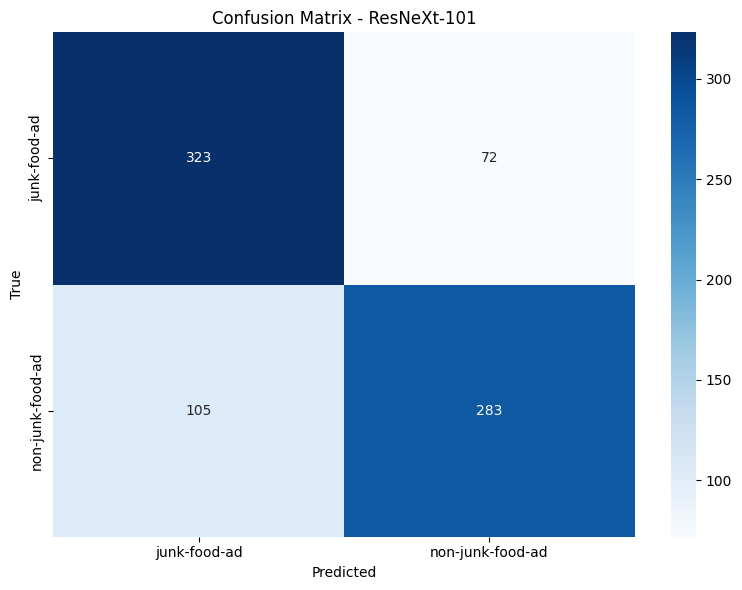


TEST SET METRICS - EfficientNet V2-M
Images: 783
Accuracy: 0.7982
Precision: 0.7855 (junk-food-ad)
Recall: 0.8253 (junk-food-ad)
F1-Score: 0.8049 (junk-food-ad)
Confusion Matrix:
[[326, 69], [89, 299]]


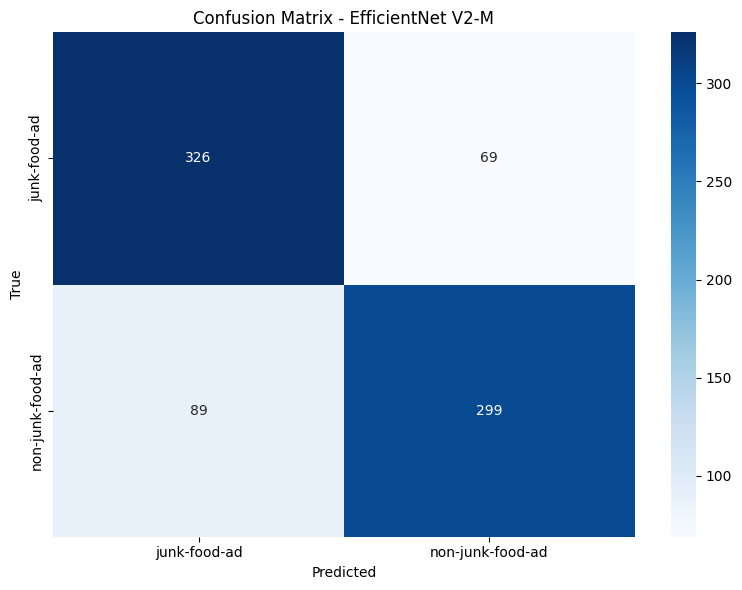


TEST SET METRICS - ConvNeXt Base
Images: 783
Accuracy: 0.8110
Precision: 0.7976 (junk-food-ad)
Recall: 0.8380 (junk-food-ad)
F1-Score: 0.8173 (junk-food-ad)
Confusion Matrix:
[[331, 64], [84, 304]]


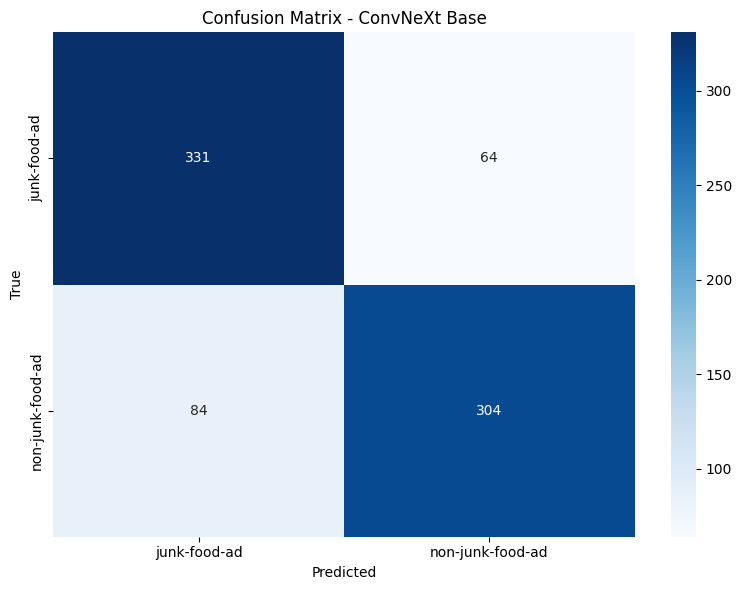


TEST SET METRICS - ViT-B/16
Images: 783
Accuracy: 0.8135
Precision: 0.7971 (junk-food-ad)
Recall: 0.8456 (junk-food-ad)
F1-Score: 0.8206 (junk-food-ad)
Confusion Matrix:
[[334, 61], [85, 303]]


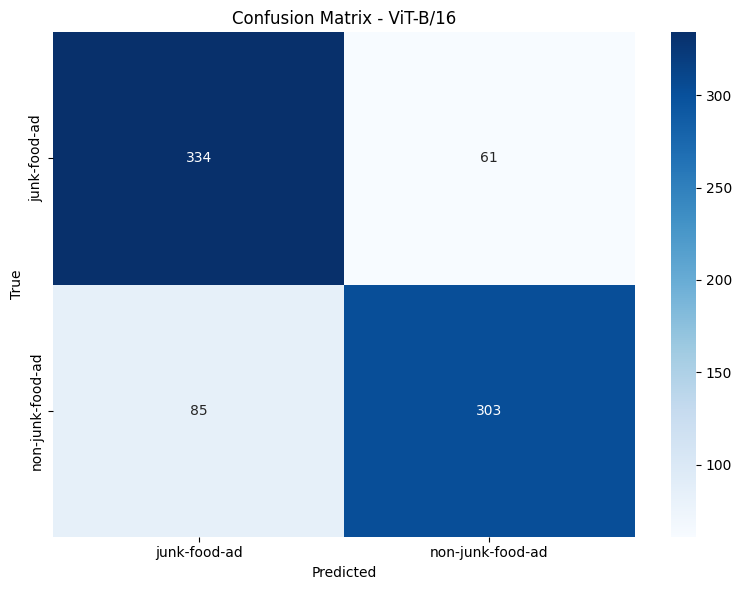


TEST SET METRICS - Swin V2-B
Images: 783
Accuracy: 0.8314
Precision: 0.8215 (junk-food-ad)
Recall: 0.8506 (junk-food-ad)
F1-Score: 0.8358 (junk-food-ad)
Confusion Matrix:
[[336, 59], [73, 315]]


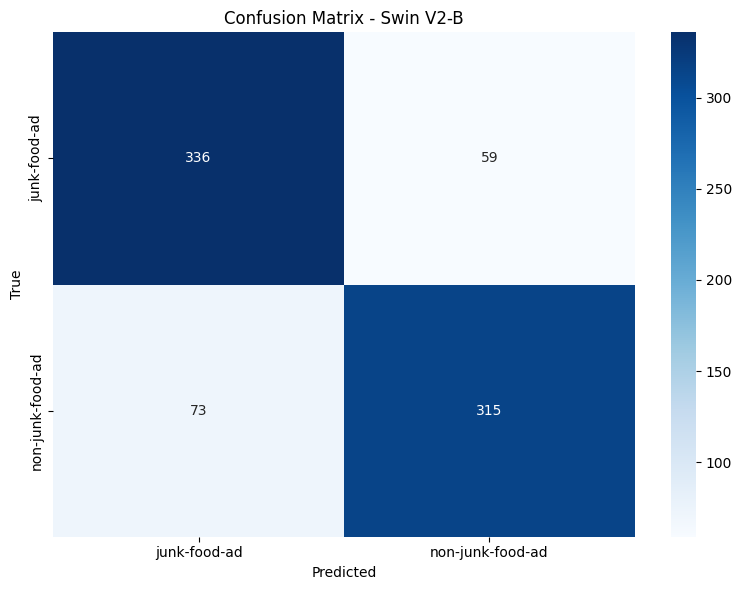


TEST SET METRICS - DINOv2
Images: 783
Accuracy: 0.8148
Precision: 0.7880 (junk-food-ad)
Recall: 0.8658 (junk-food-ad)
F1-Score: 0.8251 (junk-food-ad)
Confusion Matrix:
[[342, 53], [92, 296]]


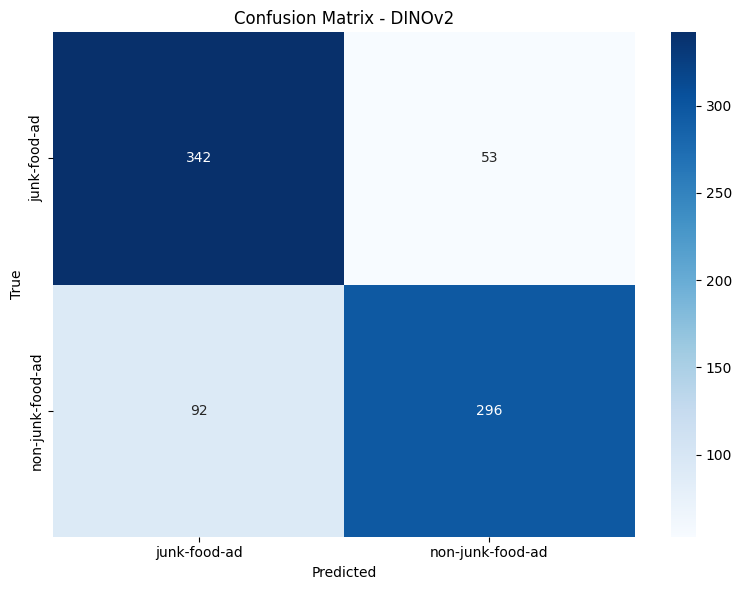

In [12]:
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

all_test_features = {}
for model_info in loaded_models:
    features = extract_features(
        image_paths_dict['test'],
        model_info['model'],
        model_info['feature_dim'],
        model_info['transform'],
        model_info['name'], 'test'
    )
    all_test_features[model_info['name']] = features

y_test = encoder.transform(labels_dict['test'])

# Evaluate all models on test set
test_results = {}
for model_name, knn in trained_models.items():
    results = evaluate_model(all_test_features[model_name], y_test, "test", knn, model_name)
    test_results[model_name] = results

    print("\n" + "="*50)
    print(f"TEST SET METRICS - {model_name}")
    print("="*50)
    print(f"Images: {results['n_images']}")
    print(f"Accuracy: {results['accuracy']:.4f}")
    print(f"Precision: {results['precision']:.4f} (junk-food-ad)")
    print(f"Recall: {results['recall']:.4f} (junk-food-ad)")
    print(f"F1-Score: {results['f1_score']:.4f} (junk-food-ad)")
    print("Confusion Matrix:")
    print(results['confusion_matrix'])

    # Plot confusion matrix
    plt.figure(figsize=(8, 6))
    sns.heatmap(
        results['confusion_matrix'],
        annot=True,
        fmt='d',
        cmap='Blues',
        xticklabels=['junk-food-ad', 'non-junk-food-ad'],
        yticklabels=['junk-food-ad', 'non-junk-food-ad']
    )
    plt.xlabel('Predicted')
    plt.ylabel('True')
    plt.title(f'Confusion Matrix - {model_name}')
    plt.tight_layout()
    plt.show()

## Export results for reporting

Download the archive before ending the Colab session. It contains full-precision validation/test metrics, class-ordered confusion matrices, a split manifest, execution metadata and a test summary CSV. Times are wall-clock seconds for this run, not epochs; training preparation is training feature extraction plus KNN fitting, excluding model loading/downloads.

In [13]:
import platform
import sklearn
import torchvision
from google.colab import files

summary_rows = []
for model_name, results in test_results.items():
    train_extraction = feature_extraction_seconds['train'][model_name]
    summary_rows.append({
        'model': model_name,
        'selected_by_validation': model_name == best_model_name,
        'n_train': len(y_train),
        'n_valid': len(y_valid),
        'n_test': len(y_test),
        'validation_f1': valid_results[model_name]['f1_score'],
        'test_accuracy': results['accuracy'],
        'test_precision': results['precision'],
        'test_recall': results['recall'],
        'test_f1': results['f1_score'],
        'train_feature_extraction_seconds': train_extraction,
        'knn_fit_seconds': fit_seconds[model_name],
        'training_preparation_seconds': train_extraction + fit_seconds[model_name],
        'valid_feature_extraction_seconds': feature_extraction_seconds['valid'][model_name],
        'test_feature_extraction_seconds': results['feature_extraction_seconds'],
        'test_prediction_seconds': results['prediction_seconds'],
    })

summary_path = os.path.join(RESULTS_PATH, 'test_summary.csv')
with open(summary_path, 'w', newline='') as f:
    writer = csv.DictWriter(f, fieldnames=list(summary_rows[0]))
    writer.writeheader()
    writer.writerows(summary_rows)

run_metadata = {
    'python': platform.python_version(),
    'torch': torch.__version__,
    'torchvision': torchvision.__version__,
    'scikit_learn': sklearn.__version__,
    'device': str(device),
    'gpu': torch.cuda.get_device_name(device) if device.type == 'cuda' else None,
    'seed': SEED,
    'split_strategy': 'group-aware stratified split of binary-dataset.zip (groups.csv); no group in more than one split',
    'split_ratios_target': SPLIT_RATIOS,
    'selected_model': best_model_name,
    'selection_criterion': 'validation F1 for junk-food-ad; first configured model breaks ties',
    'knn': {'n_neighbors': 5, 'metric': 'euclidean', 'weights': 'uniform'},
    'feature_scaling': 'none beyond extractor image preprocessing',
    'preprocessing': {config['name']: repr(config['transform']) for config in model_configs},
    'epochs': None,
    'patience': None,
    'timing_scope': 'Wall-clock extraction and fit/predict; excludes model loading and downloads',
}
with open(os.path.join(RESULTS_PATH, 'run_metadata.json'), 'w') as f:
    json.dump(run_metadata, f, indent=2)

print(f'Primary model selected on validation: {best_model_name}')
print(f'Test summary: {summary_path}')
archive_path = shutil.make_archive(os.path.join(HOME, 'knn_results'), 'zip', RESULTS_PATH)
files.download(archive_path)

Primary model selected on validation: DINOv2
Test summary: /content/runs/classify/test_summary.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Real images test

Illustrate predictions of the validation-selected model on five seeded random positive test images. These examples are qualitative, not a substitute for metrics on the entire test set. The neighbor vote fraction is not a calibrated confidence probability.

Image 1/5: /content/binary_dataset/ad/2024-04-28_canal_7_processed_40720_6.jpg


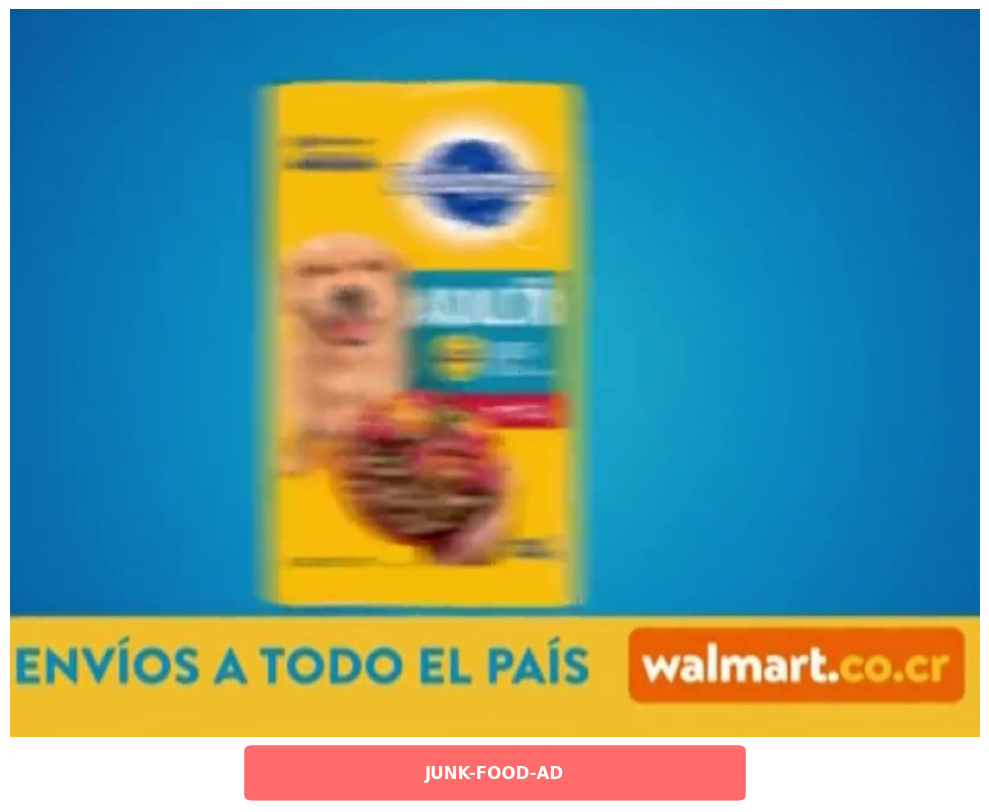

Model: DINOv2
Prediction: junk-food-ad (neighbor vote fraction: 100.00%)
True label: junk-food-ad
Correct: True
Neighbor vote fractions:
  junk-food-ad: 100.00%
  non-junk-food-ad: 0.00%
Image 2/5: /content/binary_dataset/ad/2024-05-21_canal_6_processed_31319_19.jpg


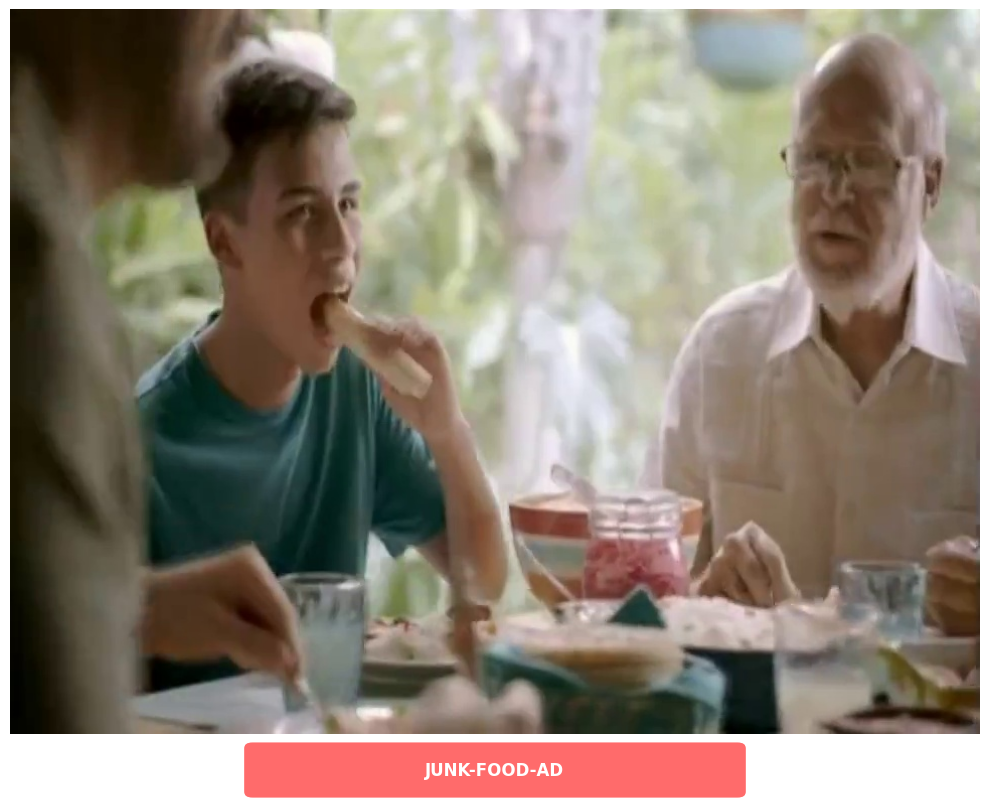

Model: DINOv2
Prediction: junk-food-ad (neighbor vote fraction: 100.00%)
True label: junk-food-ad
Correct: True
Neighbor vote fractions:
  junk-food-ad: 100.00%
  non-junk-food-ad: 0.00%
Image 3/5: /content/binary_dataset/ad/2024-05-21_canal_6_processed_31447_7.jpg


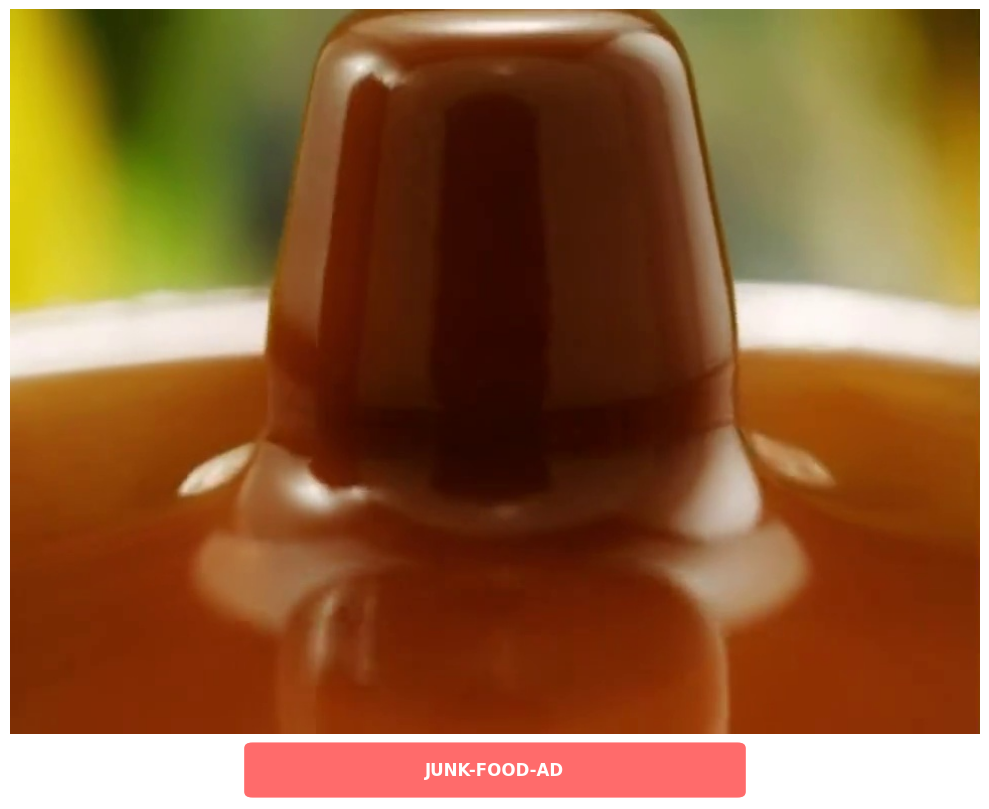

Model: DINOv2
Prediction: junk-food-ad (neighbor vote fraction: 100.00%)
True label: junk-food-ad
Correct: True
Neighbor vote fractions:
  junk-food-ad: 100.00%
  non-junk-food-ad: 0.00%
Image 4/5: /content/binary_dataset/ad/2024-05-21_canal_6_processed_31387_15.jpg


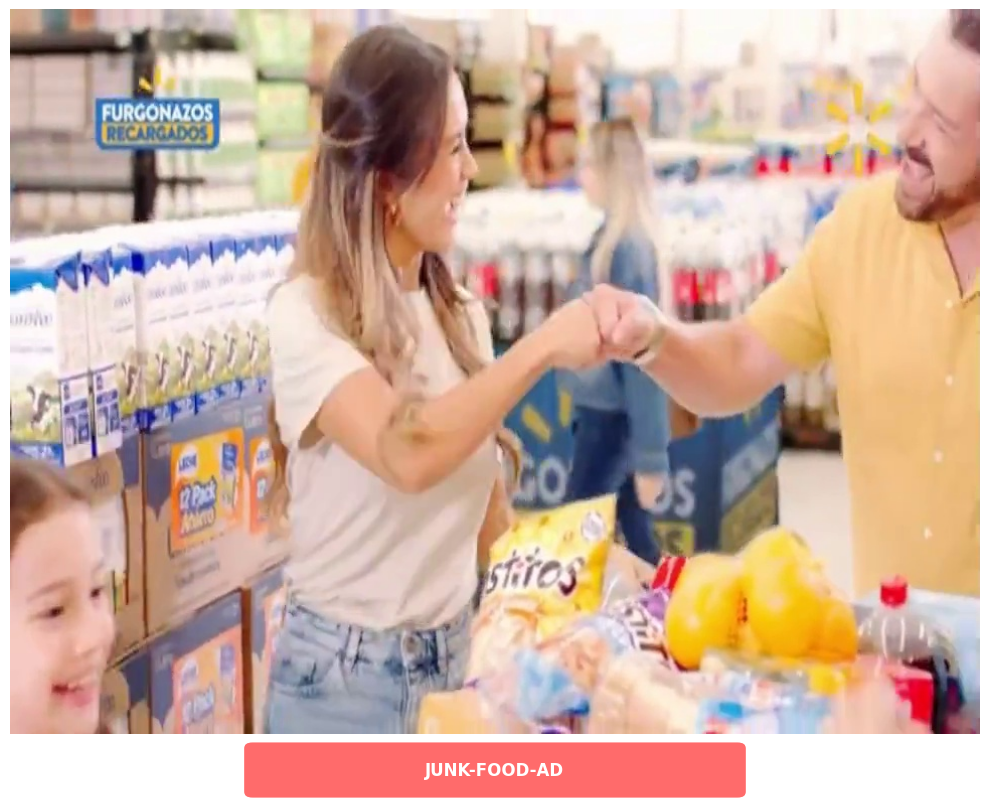

Model: DINOv2
Prediction: junk-food-ad (neighbor vote fraction: 100.00%)
True label: junk-food-ad
Correct: True
Neighbor vote fractions:
  junk-food-ad: 100.00%
  non-junk-food-ad: 0.00%
Image 5/5: /content/binary_dataset/ad/2024-04-26_canal_7_processed_40497_3.jpg


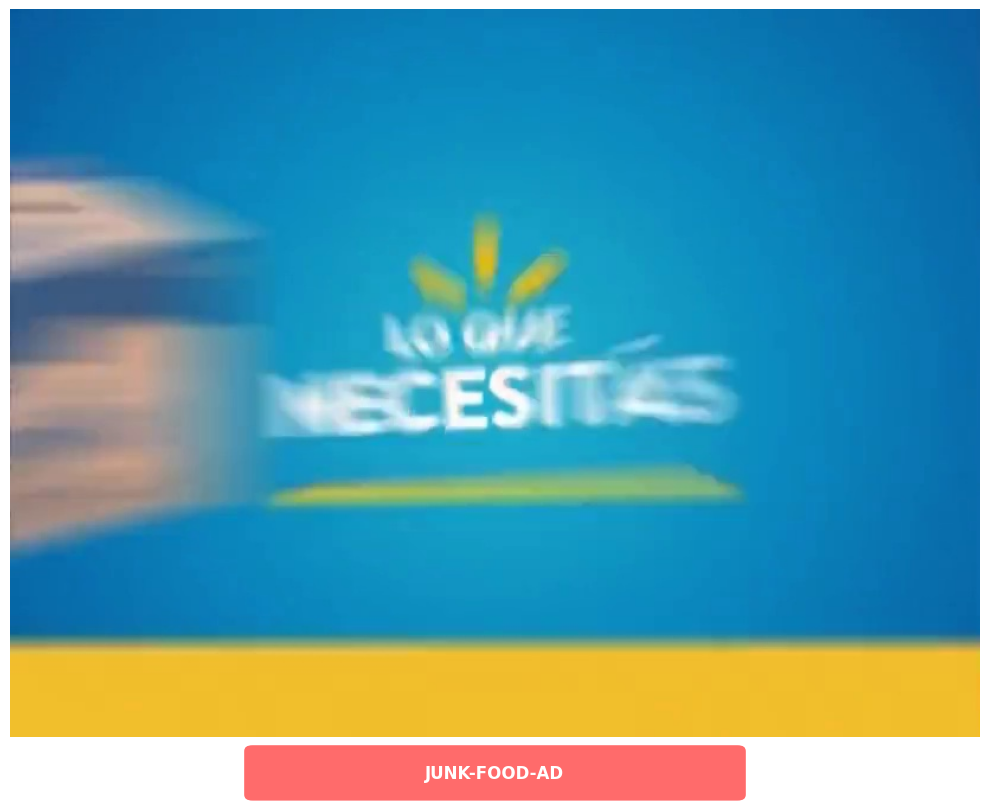

Model: DINOv2
Prediction: junk-food-ad (neighbor vote fraction: 60.00%)
True label: junk-food-ad
Correct: True
Neighbor vote fractions:
  junk-food-ad: 60.00%
  non-junk-food-ad: 40.00%


In [14]:
import random
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from PIL import Image as PILImage

best_knn = trained_models[best_model_name]

# Get indices of positive class images only (junk-food-ad)
# We only want to display interesting images that have actual junk food ads
positive_indices = [i for i, label in enumerate(labels_dict['test']) if label == 'junk-food-ad']

# Pick 5 random test images from positive class
test_indices = random.Random(SEED).sample(positive_indices, min(5, len(positive_indices)))

# Define colors for labels
colors = {
    "junk-food-ad": "#FF6B6B",      # Red
    "non-junk-food-ad": "#4ECDC4"   # Teal
}
default_color = "#95A5A6"

for idx, random_idx in enumerate(test_indices, 1):
    random_image_path = image_paths_dict['test'][random_idx]
    true_label = labels_dict['test'][random_idx]

    print(f"{'='*60}")
    print(f"Image {idx}/5: {random_image_path}")
    print('='*60)

    with PILImage.open(random_image_path) as source_image:
        image = source_image.convert("RGB")
    features = all_test_features[best_model_name][random_idx:random_idx + 1]

    # Predict
    y_pred_encoded = best_knn.predict(features)[0]
    predicted_label = encoder.inverse_transform([y_pred_encoded])[0]

    # Get prediction probabilities
    proba = best_knn.predict_proba(features)[0]
    confidence = proba.max()
    is_correct = predicted_label == true_label

    # Display the image with prediction
    fig, ax = plt.subplots(1, 1, figsize=(10, 10))
    ax.imshow(image)
    ax.axis("off")

    # Create label badge
    label_color = colors.get(predicted_label, default_color)
    label_text = predicted_label.upper()

    # Add colored badge at the bottom
    badge = mpatches.FancyBboxPatch(
        (0.25, -0.08), 0.5, 0.06,
        boxstyle="round,pad=0.01",
        facecolor=label_color,
        edgecolor="white",
        linewidth=2,
        transform=ax.transAxes,
        clip_on=False
    )
    ax.add_patch(badge)
    ax.text(
        0.5, -0.05,
        label_text,
        transform=ax.transAxes,
        fontsize=12,
        fontweight="bold",
        color="white",
        ha="center",
        va="center"
    )

    plt.tight_layout()
    plt.show()

    print(f"Model: {best_model_name}")
    print(f"Prediction: {predicted_label} (neighbor vote fraction: {confidence:.2%})")
    print(f"True label: {true_label}")
    print(f"Correct: {is_correct}")
    print(f"Neighbor vote fractions:")
    for cls_idx, cls_proba in enumerate(proba):
        cls_name = encoder.inverse_transform([cls_idx])[0]
        print(f"  {cls_name}: {cls_proba:.2%}")
